# Geometry-selected hypothesis classes in a double data re-uploading classifier

A controlled SAR-like spectral classification task in which the acquisition
geometry fixes one non-absorbable query encoding of a double data re-uploading
circuit. The experiment tests whether the geometry-selected hypothesis class
$\mathcal H(f^\star_{geom})$ is aligned with the classification rule.

**Task.** Each sample is an $8\times8$ complex phase-history patch in the
unfocused azimuth-wavenumber--range-wavenumber domain. The samples contain a
labelled point target in one of eight azimuth cells, off-range clutter,
complex Gaussian noise, and a fixed label-independent channel phase. The
patch $\boldsymbol x_j$ varies between samples, whereas the acquisition and
reference range are fixed. Hence the geometry-derived query

$$f^\star_{geom}=R_0\,\kappa_{xr}\,\Delta k_x\Delta k_r$$

is a single architectural hyperparameter shared by the complete dataset.

**Model.** Two three-qubit registers represent the azimuth and range indices.
The circuit has the double data re-uploading form

$$U_{f}(\boldsymbol x;\boldsymbol\theta)
=\prod_{\ell=1}^{L}\left[
  E^{f}_\ell(f)\,
  \bigl(V^A_\ell\otimes V^D_\ell\bigr)\,
  E^{x}_\ell(\boldsymbol x)\,
  \bigl(W^A_\ell\otimes W^D_\ell\bigr)
\right],$$

where

$$E^f_\ell(f)=\exp[-i(f/L)\,\widetilde A\widetilde D]$$

compiles into nine cross-register $R_{ZZ}$ rotations. Every trainable block
is a product across the $A|D$ partition. For generic $f$, $E^f_\ell(f)$ has
operator-Schmidt rank larger than one and therefore cannot be absorbed into
either adjacent trainable block. Changing $f$ leaves the accessible
$\boldsymbol x$-frequency support unchanged but changes how its coefficients
are coupled. Both statements are checked or audited before fitting.

**Comparisons.** The query scan holds the data fixed and fits a separate
classifier for each global $f/f^\star_{geom}$. The sample-efficiency experiment
compares the geometry-aligned query $f^\star_{geom}$, the support- and
entanglement-matched control $-f^\star_{geom}$, an $x$-only circuit with $f=0$, and
a circuit with one trainable global query. A second experiment profiles
validation loss over a grid of *fixed* queries for several acquisitions and
asks whether the independently derived $f^\star_{geom}$ predicts the optimal member
of the family $\{\mathcal H(f)\}$.

The simulation is deliberately SAR-like rather than measured raw SAR: it
isolates the nonseparable phase term of the $\omega$--$k$ relation and uses a
phase-only feature map. Set `PROFILE = "paper"` for manuscript statistics.
Results are checkpointed and resume on re-execution.


In [1]:
# =============================================================================
# Configuration
# =============================================================================
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

PROFILE = "paper"

# Two three-qubit registers: azimuth wavenumber and range wavenumber.
N = 3
Q = 2**N
NUM_QUBITS = 2 * N
DIM = Q * Q
LAYERS = 2

# X-band-like local acquisition patch. k_r is the two-way range wavenumber.
C0 = 299_792_458.0
CARRIER_HZ = 10.0e9
RANGE_FREQUENCY_STEP_HZ = 5.0e6
AZIMUTH_WAVENUMBER_CENTER = 125.0
AZIMUTH_WAVENUMBER_STEP = 1.25
REFERENCE_RANGE_M = 3700.0

# Controlled SAR-like scene model.
SNR_DB = 10.0
N_CLUTTER = 4
CLUTTER_RMS = 1.25
AZIMUTH_SUBCELL_JITTER = 0.48
CLUTTER_RANGE_RATIO = (0.45, 1.55)

# Fixed channel phase. It is learnable by the local trainable blocks but is
# not part of the geometry supplied to the circuit.
SENSOR_Z_PHASES = np.array([1.5, -1.7, 1.0])

PROFILES = {
    "smoke": dict(
        n_draws=2,
        geometry_profile_draws=1,
        geometry_profile_points=7,
        n_train_scan=128,
        n_validation=256,
        n_test=512,
        efficiency_ns=[64, 256],
        n_restarts=2,
        adam_steps=150,
        adam_lr=0.05,
        scan_points=7,
        bootstrap_samples=200,
    ),
    "paper": dict(
        n_draws=12,
        geometry_profile_draws=4,
        geometry_profile_points=15,
        n_train_scan=512,
        n_validation=1024,
        n_test=4096,
        efficiency_ns=[32, 64, 128, 256, 512],
        n_restarts=6,
        adam_steps=700,
        adam_lr=0.04,
        scan_points=15,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

EXPERIMENT_VERSION = "fixed-query-v3-profile-bootstrap"
BASE_SEED = 271828
OUTDIR = Path("./sar_fixed_query_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

print(
    f"profile={PROFILE} | {Q} classes | {LAYERS} re-uploading layers | "
    f"draws={P['n_draws']}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: its numerical values are not manuscript results.")


profile=paper | 8 classes | 2 re-uploading layers | draws=12


## Acquisition geometry and the fixed query

For a patch centred at $(k_{x0},k_{r0})$, the nonseparable part of the
$\omega$--$k$ surface $k_y=\sqrt{k_r^2-k_x^2}$ is controlled locally by

$$\kappa_{xr}
=\partial^2_{k_xk_r}k_y
=\frac{k_{x0}k_{r0}}{(k_{r0}^2-k_{x0}^2)^{3/2}}.$$

A scene at the fixed reference range $R_0$ therefore contains the bilinear
phase

$$f^\star_{geom}\,\widetilde a\widetilde d,
\qquad
f^\star_{geom}=R_0\kappa_{xr}\Delta k_x\Delta k_r.$$

The carrier, sampling increments, squint and $R_0$ are fixed before any
sample or label is drawn. Thus $f^\star_{geom}$ does not enter as sample metadata:
it selects one hypothesis class $\mathcal H(f^\star_{geom})$ for the complete task.
The exact sampled interaction is retained in the data generator, while the
circuit uses its compact bilinear approximation.


In [2]:
# =============================================================================
# Acquisition geometry and the fixed query
# =============================================================================
TWO_PI = 2 * np.pi
INDEX = np.arange(Q, dtype=float)
CENTERED = INDEX - (Q - 1) / 2
CELL_WIDTH = TWO_PI / Q

# Compact interaction implemented by the query gate.
H_COMPACT = np.outer(CENTERED, CENTERED)
H_COMPACT_FLAT = jnp.asarray(H_COMPACT.reshape(-1))
MAX_BILINEAR = float(np.max(np.abs(H_COMPACT)))


def build_geometry(
    carrier_hz=CARRIER_HZ,
    range_step_hz=RANGE_FREQUENCY_STEP_HZ,
    kx_center=AZIMUTH_WAVENUMBER_CENTER,
    kx_step=AZIMUTH_WAVENUMBER_STEP,
    reference_range=REFERENCE_RANGE_M,
    name="baseline",
):
    """Sample the local omega-k surface and derive the global query f*."""
    kr_center = 4 * np.pi * carrier_hz / C0
    delta_kr = 4 * np.pi * range_step_hz / C0
    kr = kr_center + delta_kr * CENTERED
    kx = kx_center + kx_step * CENTERED
    if not np.all(kr[None, :] ** 2 > kx[:, None] ** 2):
        raise ValueError("evanescent samples: require k_r^2 > k_x^2")

    ky = np.sqrt(kr[None, :] ** 2 - kx[:, None] ** 2)
    interaction = (
        ky
        - ky.mean(axis=1, keepdims=True)
        - ky.mean(axis=0, keepdims=True)
        + ky.mean()
    )
    kappa = kx_center * kr_center / (kr_center**2 - kx_center**2) ** 1.5
    mixed_scale = kappa * kx_step * delta_kr
    h_exact = interaction / mixed_scale
    coefficient = float(np.sum(h_exact * H_COMPACT) / np.sum(H_COMPACT**2))
    r_squared = float(
        1.0
        - np.sum((h_exact - coefficient * H_COMPACT) ** 2)
        / np.sum((h_exact - h_exact.mean()) ** 2)
    )
    return {
        "name": name,
        "carrier_hz": carrier_hz,
        "range_step_hz": range_step_hz,
        "kx_center": kx_center,
        "kx_step": kx_step,
        "reference_range": reference_range,
        "kr_center": kr_center,
        "delta_kr": delta_kr,
        "kappa_xr": kappa,
        "mixed_scale": mixed_scale,
        "f_geometry": reference_range * mixed_scale,
        "h_exact": h_exact,
        "h_exact_jax": jnp.asarray(h_exact),
        "bilinear_coefficient": coefficient,
        "bilinear_r2": r_squared,
    }


GEOMETRY = build_geometry()
F_GEOMETRY = GEOMETRY["f_geometry"]
H_EXACT = GEOMETRY["h_exact"]

# Independent acquisitions for the fixed-query profile experiment. Each
# dataset has one fixed f*. The settings span carrier, squint, bandwidth,
# and reference-range variations without changing the classification rule.
PROFILE_GEOMETRIES = [
    build_geometry(carrier_hz=14.0e9, name="high carrier"),
    build_geometry(kx_center=80.0, name="low squint"),
    GEOMETRY,
    build_geometry(reference_range=4800.0, name="far range"),
    build_geometry(kx_center=180.0, name="high squint"),
    build_geometry(range_step_hz=9.0e6, name="high bandwidth"),
    build_geometry(
        kx_center=180.0,
        range_step_hz=7.0e6,
        name="squint + bandwidth",
    ),
    build_geometry(
        carrier_hz=14.0e9,
        range_step_hz=9.0e6,
        name="carrier + bandwidth",
    ),
]

SCAN_RATIOS = np.unique(
    np.concatenate(
        [np.linspace(-1.5, 2.0, P["scan_points"]), [-1.0, 0.0, 0.5, 1.0]]
    )
)
PROFILE_QUERY_RATIOS = np.unique(
    np.concatenate(
        [
            np.linspace(-1.5, 2.0, P["geometry_profile_points"]),
            [-1.0, 0.0, 1.0],
        ]
    )
)

GEOMETRY_SUMMARY = {
    "reference_range_m": REFERENCE_RANGE_M,
    "kappa_xr_m": GEOMETRY["kappa_xr"],
    "mixed_scale_rad_per_m": GEOMETRY["mixed_scale"],
    "fixed_query_f_star_rad": F_GEOMETRY,
    "max_bilinear": MAX_BILINEAR,
    "bilinear_r2": GEOMETRY["bilinear_r2"],
}
print(pd.Series(GEOMETRY_SUMMARY).to_string(float_format=lambda v: f"{v:.6g}"))
print(
    "\nfixed queries across acquisitions (rad): "
    + ", ".join(
        f"{g['name']}={g['f_geometry']:.3f}" for g in PROFILE_GEOMETRIES
    )
)


reference_range_m               3700
kappa_xr_m               0.000818094
mixed_scale_rad_per_m    0.000214325
fixed_query_f_star_rad      0.793002
max_bilinear                   12.25
bilinear_r2                 0.999832

fixed queries across acquisitions (rad): high carrier=0.377, low squint=0.467, baseline=0.793, far range=1.029, high squint=1.348, high bandwidth=1.427, squint + bandwidth=1.887, carrier + bandwidth=0.679


## SAR-like phase-history generator

Every dataset is generated at one fixed acquisition geometry. Labels and
target positions vary between samples, but the target coupling is always
$f^\star_{geom}$. Off-range clutter uses different range factors and is therefore
not simultaneously focused by the target query. The feature map retains the
phase of the complex patch; this is a controlled spectral phase-history task,
not a claim to reproduce the complete raw-data SAR pipeline.


In [3]:
# =============================================================================
# SAR-like phase-history generator
# =============================================================================
_sensor_bits = (np.arange(Q)[:, None] >> np.arange(N - 1, -1, -1)[None, :]) & 1
_sensor_z = 1.0 - 2.0 * _sensor_bits
SENSOR_PHASE = np.exp(-0.5j * (_sensor_z @ SENSOR_Z_PHASES))
SENSOR_PHASE_JAX = jnp.asarray(SENSOR_PHASE)
INDEX_JAX = jnp.asarray(INDEX)


def seed_from(*parts):
    sequence = np.random.SeedSequence([BASE_SEED, *[int(p) for p in parts]])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def balanced_labels(key, batch_size):
    if batch_size % Q:
        raise ValueError(f"batch_size={batch_size} must be divisible by Q={Q}")
    scores = jax.random.uniform(key, (batch_size // Q, Q))
    return jnp.argsort(scores, axis=1).reshape(-1)


def scenes(
    key,
    batch_size,
    geometry=None,
    *,
    snr_db=SNR_DB,
    n_clutter=N_CLUTTER,
    clutter_rms=CLUTTER_RMS,
    azimuth_jitter=AZIMUTH_SUBCELL_JITTER,
):
    """Return complex phase-history patches and labels at one fixed f*."""
    geometry = GEOMETRY if geometry is None else geometry
    h_exact = geometry["h_exact_jax"]
    f_geometry = geometry["f_geometry"]

    keys = jax.random.split(key, 11)
    labels = balanced_labels(keys[0], batch_size)
    u_target = jnp.mod(
        TWO_PI * labels / Q
        + azimuth_jitter
        * CELL_WIDTH
        * jax.random.uniform(keys[1], (batch_size,), minval=-1.0, maxval=1.0),
        TWO_PI,
    )
    v_target = jax.random.uniform(
        keys[2], (batch_size,), minval=0.0, maxval=TWO_PI
    )
    reflectivity = jnp.exp(
        1j * jax.random.uniform(keys[3], (batch_size,), minval=0.0, maxval=TWO_PI)
    )

    target = reflectivity[:, None, None] * jnp.exp(
        -1j
        * (
            u_target[:, None, None] * INDEX_JAX[None, :, None]
            + v_target[:, None, None] * INDEX_JAX[None, None, :]
        )
        + 1j * f_geometry * h_exact[None, :, :]
    )

    if n_clutter:
        u_clutter = jax.random.uniform(
            keys[4], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        v_clutter = jax.random.uniform(
            keys[5], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        range_ratio = jax.random.uniform(
            keys[6],
            (batch_size, n_clutter),
            minval=CLUTTER_RANGE_RATIO[0],
            maxval=CLUTTER_RANGE_RATIO[1],
        )
        clutter_reflectivity = (
            clutter_rms
            / np.sqrt(2 * n_clutter)
            * (
                jax.random.normal(keys[7], (batch_size, n_clutter))
                + 1j * jax.random.normal(keys[8], (batch_size, n_clutter))
            )
        )
        clutter_phase = (
            -1j
            * (
                u_clutter[:, :, None, None] * INDEX_JAX[None, None, :, None]
                + v_clutter[:, :, None, None] * INDEX_JAX[None, None, None, :]
            )
            + 1j
            * (f_geometry * range_ratio)[:, :, None, None]
            * h_exact[None, None, :, :]
        )
        clutter = jnp.sum(
            clutter_reflectivity[:, :, None, None] * jnp.exp(clutter_phase), axis=1
        )
    else:
        clutter = jnp.zeros_like(target)

    signal = target + clutter
    rms = jnp.sqrt(jnp.mean(jnp.abs(signal) ** 2, axis=(1, 2), keepdims=True))
    sigma = rms * 10 ** (-snr_db / 20) / np.sqrt(2)
    noise = sigma * (
        jax.random.normal(keys[9], signal.shape)
        + 1j * jax.random.normal(keys[10], signal.shape)
    )
    signal = (signal + noise) * SENSOR_PHASE_JAX[None, :, None]
    return signal, labels


def encode(signal):
    """Phase-only variables uploaded by E_x."""
    return jnp.angle(signal).reshape(signal.shape[0], DIM)


print("fixed-geometry scene model loaded")


fixed-geometry scene model loaded


## Non-absorbable double data re-uploading circuit

The trainable blocks contain arbitrary single-qubit $R_YR_Z$ layers and
fixed CZ rings *within* each register, but never couple the azimuth and range
registers. They therefore have the form $U_A\otimes U_D$. By contrast,

$$E^f(f)=\operatorname{diag}_{a,d}
\left(e^{-if\widetilde a\widetilde d}\right)$$

is nonproduct for $f\notin2\pi\mathbb Z$: its diagonal coefficient matrix has
rank larger than one. Hence a fixed geometry query cannot be absorbed into
an adjacent trainable block. The wrong-sign control $-f^\star_{geom}$ has exactly
the same operator-Schmidt spectrum and gate count as the aligned query.

At zero parameters, the four within-register CZ rings cancel and the circuit
reduces to the product of its two re-uploaded encodings. The only optional
extra parameter is the single global query used by the trainable-query arm.


In [4]:
# =============================================================================
# Non-absorbable double data re-uploading circuit and training
# =============================================================================
PARAMETERS_PER_LAYER = 4 * NUM_QUBITS  # W(12) + V(12)
N_VARIATIONAL_PARAMETERS = LAYERS * PARAMETERS_PER_LAYER
N_PARAMETERS = N_VARIATIONAL_PARAMETERS + 1  # optional learned global query
QUERY_BOUND = 1.25 * np.pi

_I2 = jnp.eye(2, dtype=jnp.complex128)


def _ry(angle):
    c, s = jnp.cos(angle / 2), jnp.sin(angle / 2)
    return jnp.array([[c, -s], [s, c]], dtype=jnp.complex128)


def _rz(angle):
    return jnp.diag(
        jnp.array([jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)])
    )


def register_cz_diagonal():
    """CZ cycles within A and D, with no cross-register coupling."""
    diagonal = np.ones(DIM)
    edges = []
    for offset in (0, N):
        edges.extend(
            (offset + qubit, offset + (qubit + 1) % N) for qubit in range(N)
        )
    for state in range(DIM):
        bits = [(state >> (NUM_QUBITS - 1 - q)) & 1 for q in range(NUM_QUBITS)]
        phase = 1
        for left, right in edges:
            if bits[left] and bits[right]:
                phase *= -1
        diagonal[state] = phase
    return jnp.asarray(diagonal, dtype=jnp.complex128)


REGISTER_CZ = register_cz_diagonal()
FOURIER = jnp.asarray(
    np.exp(2j * np.pi * np.outer(INDEX, INDEX) / Q) / np.sqrt(Q)
)

# Binary weights in A~=-(1/2)sum_i w_i Z_i and similarly for D~.
Z_CROSS = jnp.asarray(
    np.einsum("ai,dj->adij", _sensor_z, _sensor_z).reshape(DIM, N * N)
)
RZZ_WEIGHTS = np.outer(
    2.0 ** np.arange(N - 1, -1, -1),
    2.0 ** np.arange(N - 1, -1, -1),
).reshape(-1)


def single_qubit_layer(angles):
    unitary = jnp.eye(1, dtype=jnp.complex128)
    for qubit in range(NUM_QUBITS):
        unitary = jnp.kron(
            unitary, _rz(angles[qubit, 1]) @ _ry(angles[qubit, 0])
        )
    return unitary


def trainable_block(angles):
    """A product U_A x U_D with entanglers only within each register."""
    return REGISTER_CZ[:, None] * single_qubit_layer(angles)


def unpack(parameters):
    parameters = jnp.asarray(parameters)
    layers = []
    for layer in range(LAYERS):
        offset = layer * PARAMETERS_PER_LAYER
        layers.append(
            (
                parameters[offset : offset + 2 * NUM_QUBITS].reshape(
                    NUM_QUBITS, 2
                ),
                parameters[
                    offset + 2 * NUM_QUBITS : offset + 4 * NUM_QUBITS
                ].reshape(NUM_QUBITS, 2),
            )
        )
    return layers, parameters[-1]


def resolved_query(parameters, base_query=0.0, learn_query=0.0):
    _, query_raw = unpack(parameters)
    learned = QUERY_BOUND * jnp.tanh(query_raw)
    return base_query + learn_query * learned


def circuit_state(parameters, phases, base_query=0.0, learn_query=0.0):
    """Amplitudes after the fixed azimuth Fourier readout."""
    layers, _ = unpack(parameters)
    query = resolved_query(parameters, base_query, learn_query)
    psi = jnp.ones((phases.shape[0], DIM), dtype=jnp.complex128) / np.sqrt(DIM)
    x_upload = jnp.exp(1j * phases / LAYERS)
    f_upload = jnp.exp(-1j * (query / LAYERS) * H_COMPACT_FLAT)
    for w_angles, v_angles in layers:
        psi = psi @ trainable_block(w_angles).T
        psi = psi * x_upload
        psi = psi @ trainable_block(v_angles).T
        psi = psi * f_upload[None, :]
    return jnp.einsum("ja,bad->bjd", FOURIER, psi.reshape(-1, Q, Q))


def probabilities(parameters, phases, base_query=0.0, learn_query=0.0):
    amplitudes = circuit_state(parameters, phases, base_query, learn_query)
    p = jnp.sum(jnp.abs(amplitudes) ** 2, axis=2)
    p = jnp.clip(p, 1e-12, None)
    return p / p.sum(axis=1, keepdims=True)


def cross_entropy(parameters, phases, labels, base_query, learn_query):
    p = probabilities(parameters, phases, base_query, learn_query)
    return -jnp.mean(jnp.log(p[jnp.arange(labels.shape[0]), labels]))


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=int)
    predictions = np.asarray(predictions, dtype=int)
    return float(
        np.mean([np.mean(predictions[labels == cls] == cls) for cls in range(Q)])
    )


def calibration_parameters():
    """Known inverse channel phase, used only for pre-training audits."""
    parameters = np.zeros(N_PARAMETERS)
    for qubit in range(N):
        parameters[2 * qubit + 1] = -SENSOR_Z_PHASES[qubit]
    return parameters


ARMS = ("aligned", "mismatched", "none", "learned")


def arm_setting(arm, f_geometry):
    if arm == "aligned":
        return float(f_geometry), 0.0
    if arm == "mismatched":
        return float(-f_geometry), 0.0
    if arm == "none":
        return 0.0, 0.0
    if arm == "learned":
        return 0.0, 1.0
    raise ValueError(f"unknown arm={arm!r}")


def make_adam_runner(steps, learning_rate):
    loss_and_gradient = jax.vmap(
        jax.value_and_grad(cross_entropy), in_axes=(0, None, None, None, None)
    )
    loss_batch = jax.vmap(
        cross_entropy, in_axes=(0, None, None, None, None)
    )

    @jax.jit
    def run(initial_parameters, phases, labels, base_query, learn_query):
        parameters = jnp.asarray(initial_parameters)
        first = jnp.zeros_like(parameters)
        second = jnp.zeros_like(parameters)
        best_parameters = parameters
        best_losses = loss_batch(
            parameters, phases, labels, base_query, learn_query
        )

        def body(step, state):
            parameters, first, second, best_parameters, best_losses = state
            _, gradient = loss_and_gradient(
                parameters, phases, labels, base_query, learn_query
            )
            norm = jnp.linalg.norm(gradient, axis=1)
            gradient = gradient * jnp.minimum(
                1.0, 10.0 / (norm + 1e-12)
            )[:, None]
            first = 0.9 * first + 0.1 * gradient
            second = 0.999 * second + 0.001 * gradient**2
            t = step + 1
            first_hat = first / (1.0 - 0.9**t)
            second_hat = second / (1.0 - 0.999**t)
            fraction = step / jnp.maximum(1, steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_hat / (
                jnp.sqrt(second_hat) + 1e-8
            )
            new_losses = loss_batch(
                parameters, phases, labels, base_query, learn_query
            )
            improved = new_losses < best_losses
            best_losses = jnp.where(improved, new_losses, best_losses)
            best_parameters = jnp.where(
                improved[:, None], parameters, best_parameters
            )
            return parameters, first, second, best_parameters, best_losses

        _, _, _, best_parameters, best_losses = jax.lax.fori_loop(
            0,
            steps,
            body,
            (parameters, first, second, best_parameters, best_losses),
        )
        return best_parameters, best_losses

    return run


ADAM_RUNNER = make_adam_runner(P["adam_steps"], P["adam_lr"])


def paired_initializations(seed, *, learned_query):
    rng = np.random.default_rng(seed)
    parameters = 0.15 * rng.normal(size=(P["n_restarts"], N_PARAMETERS))
    parameters[0] = 0.0
    parameters[:, -1] = (
        rng.uniform(-1.0, 1.0, size=P["n_restarts"])
        if learned_query
        else 0.0
    )
    if learned_query:
        parameters[0, -1] = 0.0
    return parameters


def fit_circuit(
    train_phases,
    train_labels,
    *,
    seed,
    base_query=0.0,
    learn_query=0.0,
    test_phases=None,
    test_labels=None,
):
    initial = paired_initializations(seed, learned_query=bool(learn_query))
    candidates, losses = ADAM_RUNNER(
        jnp.asarray(initial),
        train_phases,
        train_labels,
        float(base_query),
        float(learn_query),
    )
    losses = np.asarray(losses)
    best_index = int(np.argmin(losses))
    best = np.asarray(candidates[best_index])
    fitted_query = float(
        resolved_query(best, float(base_query), float(learn_query))
    )
    result = {
        "train_loss": float(losses[best_index]),
        "best_restart": best_index,
        "fitted_query": fitted_query,
    }
    if test_phases is not None:
        p = np.asarray(
            probabilities(best, test_phases, base_query, learn_query)
        )
        labels = np.asarray(test_labels, dtype=int)
        prediction = np.argmax(p, axis=1)
        result.update(
            test_accuracy=float(np.mean(prediction == labels)),
            test_balanced_accuracy=balanced_accuracy(labels, prediction),
            test_nll=float(-np.mean(np.log(p[np.arange(len(labels)), labels]))),
        )
    return result


print(
    f"circuit loaded | {N_VARIATIONAL_PARAMETERS} variational parameters "
    "+ optional global query"
)


circuit loaded | 48 variational parameters + optional global query


## Validity gates

These checks run before fitting. In addition to the geometry and compilation
tests, they certify the architectural premise: every trainable block has
operator-Schmidt rank one across the azimuth--range partition, whereas every
geometry query used in the experiment has rank larger than one. The fixed
query therefore cannot be absorbed into an adjacent trainable block. The
aligned and wrong-sign gates are also checked to have identical
operator-Schmidt spectra.


In [5]:
# =============================================================================
# Validity gates
# =============================================================================
VALIDITY = {}

# 1. Analytic mixed derivative against a central finite difference.
epsilon = 1e-3
ky_scalar = lambda kx, kr: np.sqrt(kr**2 - kx**2)
kx0, kr0 = AZIMUTH_WAVENUMBER_CENTER, GEOMETRY["kr_center"]
finite_mixed = (
    ky_scalar(kx0 + epsilon, kr0 + epsilon)
    - ky_scalar(kx0 + epsilon, kr0 - epsilon)
    - ky_scalar(kx0 - epsilon, kr0 + epsilon)
    + ky_scalar(kx0 - epsilon, kr0 - epsilon)
) / (4 * epsilon**2)
VALIDITY["mixed derivative relative error"] = float(
    abs(finite_mixed - GEOMETRY["kappa_xr"]) / abs(GEOMETRY["kappa_xr"])
)
assert VALIDITY["mixed derivative relative error"] < 2e-5

# 2. Bilinear quality for every acquisition.
for geometry in PROFILE_GEOMETRIES:
    h = geometry["h_exact"]
    assert np.max(np.abs(h.mean(axis=1))) < 1e-8
    assert np.max(np.abs(h.mean(axis=0))) < 1e-8
    assert abs(geometry["bilinear_coefficient"] - 1.0) < 0.01
    assert geometry["bilinear_r2"] > 0.995
VALIDITY["worst bilinear R2"] = float(
    min(g["bilinear_r2"] for g in PROFILE_GEOMETRIES)
)
VALIDITY["worst aligned residual rad"] = float(
    max(
        np.max(
            np.abs(g["f_geometry"] * (g["h_exact"] - H_COMPACT))
        )
        for g in PROFILE_GEOMETRIES
    )
)
# R^2 alone can hide a physically relevant phase error when f is large.
# Keep every acquisition inside the regime where the compact interaction
# is a quantitatively faithful approximation to the exact sampled surface.
assert VALIDITY["worst aligned residual rad"] < 0.35

# 3. The compact query is exactly n^2 cross-register RZZ rotations.
theta = 0.731
compiled = np.zeros(DIM)
for index, weight in enumerate(RZZ_WEIGHTS):
    compiled += -0.5 * (theta * weight / 2.0) * np.asarray(Z_CROSS)[:, index]
VALIDITY["RZZ decomposition"] = float(
    np.max(
        np.abs(
            np.exp(1j * compiled)
            - np.exp(-1j * theta * H_COMPACT).reshape(-1)
        )
    )
)
VALIDITY["RZZ gates per upload"] = N * N
assert VALIDITY["RZZ decomposition"] < 1e-12

# 4. Operator-Schmidt certificates across A|D.
def diagonal_operator_schmidt_spectrum(query):
    matrix = np.exp(-1j * query * H_COMPACT)
    return np.linalg.svd(matrix, compute_uv=False)


def unitary_operator_schmidt_spectrum(unitary):
    tensor = np.asarray(unitary).reshape(Q, Q, Q, Q)
    reshaped = tensor.transpose(0, 2, 1, 3).reshape(Q * Q, Q * Q)
    return np.linalg.svd(reshaped, compute_uv=False)


rng = np.random.default_rng(seed_from(20))
probe_angles = rng.normal(size=(NUM_QUBITS, 2))
trainable_s = unitary_operator_schmidt_spectrum(trainable_block(probe_angles))
VALIDITY["trainable block Schmidt residual"] = float(
    np.sqrt(np.sum(trainable_s[1:] ** 2) / np.sum(trainable_s**2))
)
assert VALIDITY["trainable block Schmidt residual"] < 1e-10

minimum_query_rank = DIM
minimum_query_residual = 1.0
maximum_sign_spectrum_error = 0.0
for geometry in PROFILE_GEOMETRIES:
    per_upload = geometry["f_geometry"] / LAYERS
    positive = diagonal_operator_schmidt_spectrum(per_upload)
    negative = diagonal_operator_schmidt_spectrum(-per_upload)
    rank = int(np.sum(positive > 1e-10 * positive[0]))
    residual = float(np.sqrt(np.sum(positive[1:] ** 2) / np.sum(positive**2)))
    minimum_query_rank = min(minimum_query_rank, rank)
    minimum_query_residual = min(minimum_query_residual, residual)
    maximum_sign_spectrum_error = max(
        maximum_sign_spectrum_error, float(np.max(np.abs(positive - negative)))
    )
VALIDITY["minimum query operator-Schmidt rank"] = minimum_query_rank
VALIDITY["minimum query product residual"] = minimum_query_residual
VALIDITY["sign-control Schmidt-spectrum error"] = maximum_sign_spectrum_error
assert VALIDITY["minimum query operator-Schmidt rank"] > 1
assert VALIDITY["minimum query product residual"] > 0.05
assert VALIDITY["sign-control Schmidt-spectrum error"] < 1e-12

# 5. At zero parameters the four within-register CZ rings cancel.
probe_signal, probe_labels = scenes(jax.random.PRNGKey(seed_from(21)), 8 * Q)
probe_phases = encode(probe_signal)
analytic = np.abs(
    np.einsum(
        "ja,bad->bjd",
        np.asarray(FOURIER),
        (
            np.exp(1j * np.asarray(probe_phases))
            * np.exp(-1j * F_GEOMETRY * H_COMPACT_FLAT)[None, :]
        ).reshape(-1, Q, Q)
        / np.sqrt(DIM),
    )
) ** 2
analytic = analytic.sum(axis=2)
VALIDITY["zero-parameter circuit is encoding product"] = float(
    np.max(
        np.abs(
            np.asarray(
                probabilities(
                    np.zeros(N_PARAMETERS), probe_phases, F_GEOMETRY, 0.0
                )
            )
            - analytic / analytic.sum(axis=1, keepdims=True)
        )
    )
)
assert VALIDITY["zero-parameter circuit is encoding product"] < 1e-10

# 6. The aligned class contains the ideal focusing solution.
CALIBRATION = calibration_parameters()
clean_signal, clean_labels = scenes(
    jax.random.PRNGKey(seed_from(22)), 8 * Q, snr_db=60.0, n_clutter=0
)
clean_phases = encode(clean_signal)
VALIDITY["clean calibrated aligned accuracy"] = balanced_accuracy(
    clean_labels,
    np.argmax(
        np.asarray(probabilities(CALIBRATION, clean_phases, F_GEOMETRY, 0.0)),
        axis=1,
    ),
)
assert VALIDITY["clean calibrated aligned accuracy"] > 0.95

# 7. The intended fixed-query contrast exists before fitting.
audit_signal, audit_labels = scenes(jax.random.PRNGKey(seed_from(23)), 800)
audit_phases = encode(audit_signal)
UNTRAINED_ACCURACY = {}
for arm in ("aligned", "mismatched", "none"):
    query, learn = arm_setting(arm, F_GEOMETRY)
    UNTRAINED_ACCURACY[arm] = balanced_accuracy(
        audit_labels,
        np.argmax(
            np.asarray(probabilities(CALIBRATION, audit_phases, query, learn)),
            axis=1,
        ),
    )
VALIDITY.update(
    {f"calibrated accuracy {arm}": value for arm, value in UNTRAINED_ACCURACY.items()}
)
assert UNTRAINED_ACCURACY["aligned"] > UNTRAINED_ACCURACY["none"] + 0.20
assert UNTRAINED_ACCURACY["aligned"] > UNTRAINED_ACCURACY["mismatched"] + 0.15

# 8. All declared training and test sets are balanced.
for size in set(
    [P["n_train_scan"], P["n_validation"], P["n_test"], *P["efficiency_ns"]]
):
    _, labels = scenes(jax.random.PRNGKey(seed_from(24, size)), size)
    counts = np.bincount(np.asarray(labels), minlength=Q)
    assert counts.max() == counts.min()
VALIDITY["balanced declared sizes"] = True
VALIDITY["query fixed within each dataset"] = True

for key, value in VALIDITY.items():
    if isinstance(value, (bool, np.bool_)):
        print(f"{key:48s} {value}")
    else:
        print(f"{key:48s} {value:.6g}")
print("all validity gates passed")


mixed derivative relative error                  4.06547e-06
worst bilinear R2                                0.999696
worst aligned residual rad                       0.320268
RZZ decomposition                                8.74301e-16
RZZ gates per upload                             9
trainable block Schmidt residual                 1.18761e-16
minimum query operator-Schmidt rank              8
minimum query product residual                   0.699599
sign-control Schmidt-spectrum error              0
zero-parameter circuit is encoding product       1.66533e-16
clean calibrated aligned accuracy                1
calibrated accuracy aligned                      0.805
calibrated accuracy mismatched                   0.04125
calibrated accuracy none                         0.12375
balanced declared sizes                          True
query fixed within each dataset                  True
all validity gates passed


## Experiments

The first scan compares the fixed-query hypothesis classes $\mathcal H(f)$
on exactly the same samples. The second experiment repeats this comparison
across acquisition geometries: for every geometry and independent draw,
$\boldsymbol\theta$ is retrained at each fixed query and the profile minimum
is selected using held-out validation loss. This separates selection among
$\{\mathcal H(f)\}$ from joint non-identifiability of $f$ and
$\boldsymbol\theta$. The final panel compares sample efficiency for aligned,
wrong-sign, $x$-only, and trainable-global-query circuits using paired
datasets and initializations.


In [6]:
# =============================================================================
# Experiment runner
# =============================================================================
RUN_SPEC = {
    "experiment_version": EXPERIMENT_VERSION,
    "profile": PROFILE,
    "register_qubits": N,
    "layers": LAYERS,
    "n_variational_parameters": N_VARIATIONAL_PARAMETERS,
    "query_bound": QUERY_BOUND,
    "geometry": {
        key: value
        for key, value in GEOMETRY.items()
        if isinstance(value, (int, float, str))
    },
    "profile_geometries": [
        {
            key: g[key]
            for key in (
                "name",
                "carrier_hz",
                "range_step_hz",
                "kx_center",
                "kx_step",
                "reference_range",
                "f_geometry",
                "bilinear_r2",
            )
        }
        for g in PROFILE_GEOMETRIES
    ],
    "snr_db": SNR_DB,
    "n_clutter": N_CLUTTER,
    "clutter_rms": CLUTTER_RMS,
    "azimuth_subcell_jitter": AZIMUTH_SUBCELL_JITTER,
    "sensor_z_phases": SENSOR_Z_PHASES.tolist(),
    "clutter_range_ratio": list(CLUTTER_RANGE_RATIO),
    "profile_settings": P,
    "scan_ratios": SCAN_RATIOS.tolist(),
    "profile_query_ratios": PROFILE_QUERY_RATIOS.tolist(),
    "base_seed": BASE_SEED,
}
RUN_ID = hashlib.sha256(
    json.dumps(RUN_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
RAW_PATH = OUTDIR / f"sar_fixed_query_{PROFILE}_{RUN_ID}.csv"
CONFIG_PATH = OUTDIR / f"sar_fixed_query_{PROFILE}_{RUN_ID}_config.json"
CONFIG_PATH.write_text(json.dumps(RUN_SPEC, indent=2))

RAW_COLUMNS = [
    "run_id",
    "task_id",
    "experiment",
    "draw",
    "geometry",
    "f_geometry",
    "arm",
    "query_value",
    "query_ratio",
    "fitted_query",
    "n_train",
    "train_loss",
    "best_restart",
    "test_accuracy",
    "test_balanced_accuracy",
    "test_nll",
    "validation_balanced_accuracy",
    "validation_nll",
]


def completed_tasks():
    if not RAW_PATH.exists():
        return set()
    return set(pd.read_csv(RAW_PATH)["task_id"].astype(str))


def append_result(row):
    complete = {column: row.get(column, np.nan) for column in RAW_COLUMNS}
    pd.DataFrame([complete], columns=RAW_COLUMNS).to_csv(
        RAW_PATH, mode="a", header=not RAW_PATH.exists(), index=False
    )


def run_all_experiments():
    completed = completed_tasks()
    start = time.time()

    # --------------------------------------------------- global query scan --
    for draw in range(P["n_draws"]):
        train_signal, train_labels = scenes(
            jax.random.PRNGKey(seed_from(100, draw)), P["n_train_scan"]
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(101, draw)), P["n_test"]
        )
        train_phases, test_phases = encode(train_signal), encode(test_signal)
        paired_seed = seed_from(102, draw)
        for index, ratio in enumerate(SCAN_RATIOS):
            task_id = f"scan-d{draw:03d}-r{index:03d}"
            if task_id in completed:
                continue
            query = float(ratio * F_GEOMETRY)
            result = fit_circuit(
                train_phases,
                train_labels,
                seed=paired_seed,
                base_query=query,
                test_phases=test_phases,
                test_labels=test_labels,
            )
            append_result(
                {
                    "run_id": RUN_ID,
                    "task_id": task_id,
                    "experiment": "scan",
                    "draw": draw,
                    "geometry": GEOMETRY["name"],
                    "f_geometry": F_GEOMETRY,
                    "arm": "scan",
                    "query_value": query,
                    "query_ratio": float(ratio),
                    "n_train": P["n_train_scan"],
                    **result,
                }
            )
            completed.add(task_id)
            print(
                f"scan draw={draw:02d} f/f*={ratio:+.3f} "
                f"acc={result['test_balanced_accuracy']:.3f}",
                flush=True,
            )

    # ----------------------------------------- fixed-query geometry profiles --
    for geometry_index, geometry in enumerate(PROFILE_GEOMETRIES):
        query_grid = PROFILE_QUERY_RATIOS * geometry["f_geometry"]
        for draw in range(P["geometry_profile_draws"]):
            train_signal, train_labels = scenes(
                jax.random.PRNGKey(seed_from(200, geometry_index, draw)),
                P["n_train_scan"],
                geometry,
            )
            validation_signal, validation_labels = scenes(
                jax.random.PRNGKey(seed_from(201, geometry_index, draw)),
                P["n_validation"],
                geometry,
            )
            train_phases = encode(train_signal)
            validation_phases = encode(validation_signal)
            paired_seed = seed_from(202, geometry_index, draw)
            for query_index, query in enumerate(query_grid):
                task_id = (
                    f"profile-g{geometry_index:02d}-d{draw:03d}-"
                    f"q{query_index:03d}"
                )
                if task_id in completed:
                    continue
                result = fit_circuit(
                    train_phases,
                    train_labels,
                    seed=paired_seed,
                    base_query=float(query),
                    test_phases=validation_phases,
                    test_labels=validation_labels,
                )
                validation_accuracy = result.pop("test_balanced_accuracy")
                result.pop("test_accuracy")
                validation_nll = result.pop("test_nll")
                append_result(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "geometry_profile",
                        "draw": draw,
                        "geometry": geometry["name"],
                        "f_geometry": geometry["f_geometry"],
                        "arm": "profile",
                        "query_value": float(query),
                        "query_ratio": float(query / geometry["f_geometry"]),
                        "n_train": P["n_train_scan"],
                        "validation_balanced_accuracy": validation_accuracy,
                        "validation_nll": validation_nll,
                        **result,
                    }
                )
                completed.add(task_id)
                print(
                    f"profile {geometry['name']:19s} draw={draw:02d} "
                    f"f={query:.3f} val_nll={validation_nll:.3f}",
                    flush=True,
                )

    # --------------------------------------------------- sample efficiency --
    n_max = max(P["efficiency_ns"])
    for draw in range(P["n_draws"]):
        pool_signal, pool_labels = scenes(
            jax.random.PRNGKey(seed_from(300, draw)), n_max
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(301, draw)), P["n_test"]
        )
        pool_phases, test_phases = encode(pool_signal), encode(test_signal)
        for n_train in P["efficiency_ns"]:
            paired_seed = seed_from(302, draw, n_train)
            for arm in ARMS:
                task_id = f"efficiency-d{draw:03d}-n{n_train:05d}-{arm}"
                if task_id in completed:
                    continue
                base_query, learn_query = arm_setting(arm, F_GEOMETRY)
                result = fit_circuit(
                    pool_phases[:n_train],
                    pool_labels[:n_train],
                    seed=paired_seed,
                    base_query=base_query,
                    learn_query=learn_query,
                    test_phases=test_phases,
                    test_labels=test_labels,
                )
                append_result(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "efficiency",
                        "draw": draw,
                        "geometry": GEOMETRY["name"],
                        "f_geometry": F_GEOMETRY,
                        "arm": arm,
                        "query_value": (
                            base_query if not learn_query else np.nan
                        ),
                        "query_ratio": (
                            base_query / F_GEOMETRY if not learn_query else np.nan
                        ),
                        "n_train": n_train,
                        **result,
                    }
                )
                completed.add(task_id)
            print(f"efficiency draw={draw:02d} N={n_train} complete", flush=True)

    print(f"elapsed {time.time() - start:.0f} s")


# run_all_experiments()
RAW_RESULTS = pd.read_csv(RAW_PATH)
RAW_RESULTS = RAW_RESULTS[RAW_RESULTS["run_id"] == RUN_ID].copy()
print(f"{len(RAW_RESULTS)} rows in {RAW_PATH}")


900 rows in sar_fixed_query_outputs/sar_fixed_query_paper_0033ff2273a7.csv


## Aggregation and claim audit

Uncertainty is bootstrapped over independent paired scene draws. For the
main scan, the notebook reports both pointwise bands and the bootstrap
interval of the maximizing query. For every acquisition profile,
$\widehat f$ minimizes the mean held-out validation-loss profile across
draws, with a local quadratic interpolation only when the minimum is
interior and convex. Its interval re-bootstraps the complete profile before
taking each minimum, preserving uncertainty in the nonlinear argmin.
Paired accuracy differences between the aligned model and every control are
reported at every training-set size. The trainable-query arm is treated only
as a predictive baseline; its internal query is not interpreted as a
recovered physical parameter.


{
  "scan_accuracy_peak_ratio": 1.0,
  "scan_peak_ratio_lower95": 1.0,
  "scan_peak_ratio_upper95": 1.0,
  "scan_peak_probability_at_geometry": 1.0,
  "scan_training_loss_minimum_ratio": 1.0,
  "geometry_profile_query_mae": 0.003527963207801528,
  "geometry_profile_relative_mae": 0.0036585458322361784,
  "geometry_predictions_inside_95_intervals": 7,
  "number_of_profiled_geometries": 8,
  "profile_minima_at_search_boundary": 0,
  "paired_effects_at_largest_N": {
    "mismatched": {
      "mean": 0.1380615234375,
      "lower95": 0.13220163981119792,
      "upper95": 0.14402313232421873
    },
    "none": {
      "mean": 0.2528483072916667,
      "lower95": 0.24369252522786458,
      "upper95": 0.2587483723958333
    },
    "learned": {
      "mean": 0.006937662760416667,
      "lower95": -0.0010986328125,
      "upper95": 0.0224609375
    }
  }
}

aligned - learned query at N=512: +0.007 [-0.001, +0.022]


,geometry,f_geometry,f_hat,f_lower95,f_upper95,profile_lower_bound,profile_upper_bound,minimum_at_boundary,relative_error,geometry_in_interval
4,high carrier,0.377220,0.375209,0.371884,0.377874,-0.565831,0.754441,False,-0.005332,True
6,low squint,0.466610,0.465101,0.463572,0.466621,-0.699916,0.933221,False,-0.003235,True
1,carrier + bandwidth,0.678997,0.678459,0.673165,0.683413,-1.018495,1.357993,False,-0.000792,True
0,baseline,0.793002,0.799052,0.796385,0.800596,-1.189502,1.586003,False,0.007630,False
2,far range,1.028759,1.031704,1.025780,1.036758,-1.543138,2.057517,False,0.002862,True
5,high squint,1.348190,1.352041,1.336293,1.377090,-2.022286,2.696381,False,0.002856,True
3,high bandwidth,1.427403,1.430702,1.422824,1.439250,-2.141104,2.854805,False,0.002312,True
7,squint + bandwidth,1.887467,1.879448,1.855366,1.901417,-2.831200,3.774933,False,-0.004248,True


,control,n_train,mean,lower95,upper95
0,mismatched,32,0.048360,0.018061,0.079387
1,mismatched,64,0.043884,0.011189,0.080323
2,mismatched,128,0.080343,0.057534,0.104390
3,mismatched,256,0.133464,0.118673,0.147013
4,mismatched,512,0.138062,0.132202,0.144023
5,none,32,0.072917,0.040709,0.106188
6,none,64,0.156494,0.126585,0.188375
7,none,128,0.193298,0.170125,0.217652
8,none,256,0.246134,0.235413,0.256246
9,none,512,0.252848,0.243693,0.258748


,query_ratio,aligned_minus_query,lower95,upper95
0,-1.50,0.245239,0.232889,0.256063
1,-1.25,0.246114,0.234720,0.256551
2,-1.00,0.136414,0.125448,0.146444
3,-0.75,0.247477,0.238464,0.256287
4,-0.50,0.245565,0.233499,0.256694
5,-0.25,0.244486,0.233276,0.253988
6,0.00,0.247131,0.235840,0.256287
7,0.25,0.246785,0.233907,0.257489
8,0.50,0.237895,0.225543,0.250264
9,0.75,0.185527,0.176228,0.195251


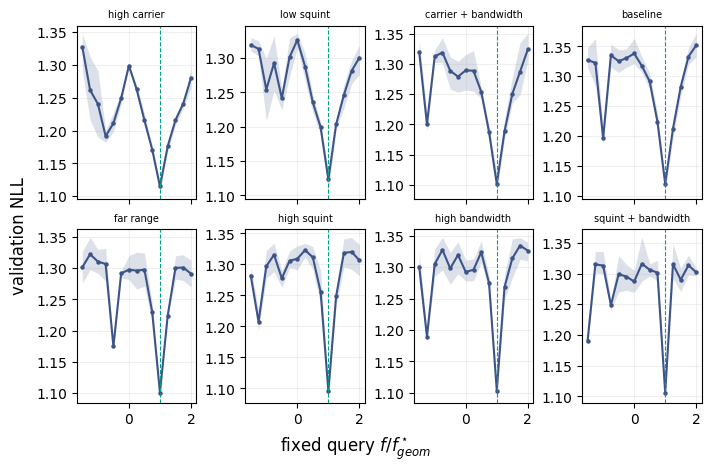

In [7]:
# =============================================================================
# Aggregation and claim audit
# =============================================================================
PRIMARY_METRIC = "test_balanced_accuracy"


def bootstrap_matrix(values, *, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed_from(500, seed))
    indices = rng.integers(
        0, values.shape[0], (P["bootstrap_samples"], values.shape[0])
    )
    draws = values[indices].mean(axis=1)
    return {
        "mean": values.mean(axis=0),
        "lower": np.quantile(draws, 0.025, axis=0),
        "upper": np.quantile(draws, 0.975, axis=0),
    }


def bootstrap_peak_interval(x, values, *, seed):
    """Bootstrap the argmax of a paired set of response curves."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed_from(510, seed))
    indices = rng.integers(
        0, values.shape[0], (P["bootstrap_samples"], values.shape[0])
    )
    means = values[indices].mean(axis=1)
    peaks = np.asarray(x)[np.argmax(means, axis=1)]
    return {
        "lower": float(np.quantile(peaks, 0.025)),
        "upper": float(np.quantile(peaks, 0.975)),
        "probability_at_geometry": float(np.mean(np.isclose(peaks, 1.0))),
    }


# -------------------------------------------------------- global query scan --
SCAN = RAW_RESULTS[RAW_RESULTS["experiment"] == "scan"]
scan_accuracy = SCAN.pivot(
    index="draw", columns="query_ratio", values=PRIMARY_METRIC
).sort_index(axis=1)
scan_loss = SCAN.pivot(
    index="draw", columns="query_ratio", values="train_loss"
).sort_index(axis=1)
SCAN_X = scan_accuracy.columns.to_numpy(dtype=float)
SCAN_SUMMARY = bootstrap_matrix(scan_accuracy.to_numpy(), seed=1)
SCAN_LOSS_SUMMARY = bootstrap_matrix(scan_loss.to_numpy(), seed=2)
SCAN_PEAK = float(SCAN_X[int(np.argmax(SCAN_SUMMARY["mean"]))])
SCAN_LOSS_MINIMUM = float(SCAN_X[int(np.argmin(SCAN_LOSS_SUMMARY["mean"]))])
SCAN_PEAK_INTERVAL = bootstrap_peak_interval(
    SCAN_X, scan_accuracy.to_numpy(), seed=3
)
aligned_index = int(np.flatnonzero(np.isclose(SCAN_X, 1.0))[0])
scan_difference = (
    scan_accuracy.to_numpy()[:, aligned_index, None]
    - scan_accuracy.to_numpy()
)
scan_difference_summary = bootstrap_matrix(scan_difference, seed=4)
SCAN_PAIRED_ADVANTAGE = pd.DataFrame(
    {
        "query_ratio": SCAN_X,
        "aligned_minus_query": scan_difference_summary["mean"],
        "lower95": scan_difference_summary["lower"],
        "upper95": scan_difference_summary["upper"],
    }
)

# --------------------------------------------- fixed-query profile minima --
def profile_minimum(query, loss):
    """Grid minimum with a local convex quadratic interpolation."""
    query = np.asarray(query, dtype=float)
    loss = np.asarray(loss, dtype=float)
    index = int(np.argmin(loss))
    if index == 0 or index == len(query) - 1:
        return float(query[index])
    local_x = query[index - 1 : index + 2]
    local_y = loss[index - 1 : index + 2]
    quadratic, linear, _ = np.polyfit(local_x, local_y, 2)
    if quadratic <= 0:
        return float(query[index])
    vertex = -linear / (2 * quadratic)
    return float(np.clip(vertex, local_x[0], local_x[-1]))


def bootstrap_profile_minimum(query, losses, *, seed):
    """Profile estimate and draw-bootstrap interval for argmin E[L(f)]."""
    query = np.asarray(query, dtype=float)
    losses = np.asarray(losses, dtype=float)
    point = profile_minimum(query, losses.mean(axis=0))
    rng = np.random.default_rng(seed_from(520, seed))
    indices = rng.integers(
        0, losses.shape[0], (P["bootstrap_samples"], losses.shape[0])
    )
    mean_profiles = losses[indices].mean(axis=1)
    minima = np.asarray(
        [profile_minimum(query, profile) for profile in mean_profiles]
    )
    return {
        "f_hat": point,
        "lower": float(np.quantile(minima, 0.025)),
        "upper": float(np.quantile(minima, 0.975)),
    }


PROFILE_RESULTS = RAW_RESULTS[
    RAW_RESULTS["experiment"] == "geometry_profile"
]
profile_rows = []
profile_curve_rows = []
profile_draw_minima = []
for geometry_index, ((name, f_geometry), part) in enumerate(
    PROFILE_RESULTS.groupby(["geometry", "f_geometry"])
):
    loss_pivot = part.pivot(
        index="draw", columns="query_value", values="validation_nll"
    ).sort_index(axis=1)
    accuracy_pivot = part.pivot(
        index="draw",
        columns="query_value",
        values="validation_balanced_accuracy",
    ).sort_index(axis=1)
    query = loss_pivot.columns.to_numpy(dtype=float)
    loss_summary = bootstrap_matrix(
        loss_pivot.to_numpy(), seed=20 + geometry_index
    )
    accuracy_summary = bootstrap_matrix(
        accuracy_pivot.to_numpy(), seed=40 + geometry_index
    )
    estimate = bootstrap_profile_minimum(
        query, loss_pivot.to_numpy(), seed=geometry_index
    )
    profile_rows.append(
        {
            "geometry": name,
            "f_geometry": float(f_geometry),
            "f_hat": estimate["f_hat"],
            "f_lower95": estimate["lower"],
            "f_upper95": estimate["upper"],
            "profile_lower_bound": float(query.min()),
            "profile_upper_bound": float(query.max()),
            "minimum_at_boundary": bool(
                np.isclose(estimate["f_hat"], query[0])
                or np.isclose(estimate["f_hat"], query[-1])
            ),
        }
    )
    for query_index, query_value in enumerate(query):
        profile_curve_rows.append(
            {
                "geometry": name,
                "f_geometry": float(f_geometry),
                "query_value": float(query_value),
                "query_ratio": float(query_value / f_geometry),
                "validation_nll": float(loss_summary["mean"][query_index]),
                "validation_nll_lower95": float(
                    loss_summary["lower"][query_index]
                ),
                "validation_nll_upper95": float(
                    loss_summary["upper"][query_index]
                ),
                "validation_balanced_accuracy": float(
                    accuracy_summary["mean"][query_index]
                ),
            }
        )
    for draw, draw_losses in zip(
        loss_pivot.index.to_numpy(), loss_pivot.to_numpy()
    ):
        profile_draw_minima.append(
            {
                "geometry": name,
                "f_geometry": float(f_geometry),
                "draw": int(draw),
                "f_hat": profile_minimum(query, draw_losses),
            }
        )

PROFILE_CURVE_SUMMARY = pd.DataFrame(profile_curve_rows)
PROFILE_DRAW_MINIMA = pd.DataFrame(profile_draw_minima)
PROFILE_SUMMARY = pd.DataFrame(profile_rows).sort_values("f_geometry")
PROFILE_SUMMARY["relative_error"] = (
    PROFILE_SUMMARY["f_hat"] - PROFILE_SUMMARY["f_geometry"]
) / PROFILE_SUMMARY["f_geometry"]
PROFILE_SUMMARY["geometry_in_interval"] = (
    (PROFILE_SUMMARY["f_lower95"] <= PROFILE_SUMMARY["f_geometry"])
    & (PROFILE_SUMMARY["f_geometry"] <= PROFILE_SUMMARY["f_upper95"])
)

# ------------------------------------------------------- sample efficiency --
EFFICIENCY = RAW_RESULTS[RAW_RESULTS["experiment"] == "efficiency"]
EFFICIENCY_SUMMARY = {}
efficiency_pivots = {}
for arm in ARMS:
    pivot = (
        EFFICIENCY[EFFICIENCY["arm"] == arm]
        .pivot(index="draw", columns="n_train", values=PRIMARY_METRIC)
        .sort_index(axis=1)
    )
    efficiency_pivots[arm] = pivot
    EFFICIENCY_SUMMARY[arm] = {
        "n": pivot.columns.to_numpy(dtype=int),
        **bootstrap_matrix(pivot.to_numpy(), seed=20 + len(EFFICIENCY_SUMMARY)),
    }

paired_rows = []
for control_index, control in enumerate(("mismatched", "none", "learned")):
    difference = (
        efficiency_pivots["aligned"].to_numpy()
        - efficiency_pivots[control].to_numpy()
    )
    summary = bootstrap_matrix(difference, seed=60 + control_index)
    for index, n_train in enumerate(efficiency_pivots["aligned"].columns):
        paired_rows.append(
            {
                "control": control,
                "n_train": int(n_train),
                "mean": float(summary["mean"][index]),
                "lower95": float(summary["lower"][index]),
                "upper95": float(summary["upper"][index]),
            }
        )
PAIRED_EFFECTS_BY_N = pd.DataFrame(paired_rows)
N_LARGEST = max(P["efficiency_ns"])
PAIRED_EFFECTS_LARGEST = PAIRED_EFFECTS_BY_N[
    PAIRED_EFFECTS_BY_N["n_train"] == N_LARGEST
].set_index("control")

profile_error = PROFILE_SUMMARY["f_hat"] - PROFILE_SUMMARY["f_geometry"]
AUDIT = {
    "scan_accuracy_peak_ratio": SCAN_PEAK,
    "scan_peak_ratio_lower95": SCAN_PEAK_INTERVAL["lower"],
    "scan_peak_ratio_upper95": SCAN_PEAK_INTERVAL["upper"],
    "scan_peak_probability_at_geometry": SCAN_PEAK_INTERVAL[
        "probability_at_geometry"
    ],
    "scan_training_loss_minimum_ratio": SCAN_LOSS_MINIMUM,
    "geometry_profile_query_mae": float(np.mean(np.abs(profile_error))),
    "geometry_profile_relative_mae": float(
        np.mean(np.abs(PROFILE_SUMMARY["relative_error"]))
    ),
    "geometry_predictions_inside_95_intervals": int(
        PROFILE_SUMMARY["geometry_in_interval"].sum()
    ),
    "number_of_profiled_geometries": int(len(PROFILE_SUMMARY)),
    "profile_minima_at_search_boundary": int(
        PROFILE_SUMMARY["minimum_at_boundary"].sum()
    ),
    "paired_effects_at_largest_N": PAIRED_EFFECTS_LARGEST[
        ["mean", "lower95", "upper95"]
    ].to_dict(orient="index"),
}
print(json.dumps(AUDIT, indent=2))

grid_step = float(np.min(np.diff(SCAN_X)))
if abs(SCAN_PEAK - 1.0) > 1.5 * grid_step:
    print(
        "\nCAUTION: accuracy does not peak near f=f*. "
        "Do not make the geometry-alignment claim."
    )
if not (
    SCAN_PEAK_INTERVAL["lower"] <= 1.0 <= SCAN_PEAK_INTERVAL["upper"]
):
    print(
        "\nCAUTION: the bootstrap peak interval excludes f=f*. "
        "Do not claim fixed-query alignment."
    )
if np.mean(np.abs(PROFILE_SUMMARY["relative_error"])) > 0.15:
    print(
        "\nCAUTION: validation-profile minima do not track the geometry "
        "within 15% on average. Do not make the geometry-scaling claim."
    )
if PROFILE_SUMMARY["minimum_at_boundary"].any():
    print(
        "\nCAUTION: at least one validation-profile minimum is at the "
        "search boundary. Expand the fixed-query profile before inference."
    )
for control in ("mismatched", "none"):
    effect = PAIRED_EFFECTS_LARGEST.loc[control]
    if effect["lower95"] <= 0:
        print(
            f"\nCAUTION: aligned - {control} is not positive at 95% "
            "draw-bootstrap confidence."
        )

learned_effect = PAIRED_EFFECTS_LARGEST.loc["learned"]
print(
    "\naligned - learned query at N={}: {:+.3f} [{:+.3f}, {:+.3f}]".format(
        N_LARGEST,
        float(learned_effect["mean"]),
        float(learned_effect["lower95"]),
        float(learned_effect["upper95"]),
    )
)
display(PROFILE_SUMMARY)
display(PAIRED_EFFECTS_BY_N)
display(SCAN_PAIRED_ADVANTAGE)

# Diagnostic rather than a manuscript panel: expose the complete profiles
# so a seemingly successful f_hat cannot hide flat or multimodal losses.
profile_names = PROFILE_SUMMARY["geometry"].tolist()
profile_columns = 4
profile_rows_count = int(np.ceil(len(profile_names) / profile_columns))
profile_figure, profile_axes = plt.subplots(
    profile_rows_count,
    profile_columns,
    figsize=(7.0, 2.3 * profile_rows_count),
    sharex=True,
    layout="constrained",
)
profile_axes = np.atleast_1d(profile_axes).ravel()
for axis, name in zip(profile_axes, profile_names):
    curve = PROFILE_CURVE_SUMMARY[
        PROFILE_CURVE_SUMMARY["geometry"] == name
    ].sort_values("query_ratio")
    axis.fill_between(
        curve["query_ratio"],
        curve["validation_nll_lower95"],
        curve["validation_nll_upper95"],
        color="#3C5488",
        alpha=0.18,
        linewidth=0,
    )
    axis.plot(
        curve["query_ratio"],
        curve["validation_nll"],
        color="#3C5488",
        marker="o",
        ms=2.2,
    )
    axis.axvline(1.0, color="#00A087", ls="--", lw=0.8)
    axis.set_title(name, fontsize=7)
    axis.grid(True, alpha=0.2)
for axis in profile_axes[len(profile_names) :]:
    axis.set_visible(False)
profile_figure.supxlabel(r"fixed query $f/f^\star_{geom}$")
profile_figure.supylabel("validation NLL")
profile_stem = OUTDIR / f"sar_fixed_query_profiles_{PROFILE}_{RUN_ID}"
profile_figure.savefig(profile_stem.with_suffix(".pdf"), bbox_inches="tight")
profile_figure.savefig(
    profile_stem.with_suffix(".png"), dpi=300, bbox_inches="tight"
)
plt.show()


## Task figure

This figure exposes the controlled mechanism without trained parameters. The
geometry query is fixed across all scenes. The aligned gate removes the
nonseparable target phase before the Fourier readout, whereas the equally
entangling wrong-sign gate reinforces it. Averaging the readout conditional
on the true class shows whether the geometry-selected representation makes
the target cell directly accessible.


In [8]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 8,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.4,
        "ytick.major.width": 0.4,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "axes.labelsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.titlesize": 8,
    }
)

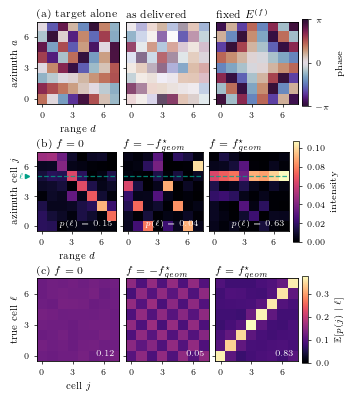

saved /home/felix/SAR-QML/notebooks/sar_fixed_query_outputs/sar_fixed_query_task_paper.pdf
{
  "example": 1,
  "label": 5,
  "fixed_query": 0.7930015007957375,
  "calibrated_accuracy": {
    "none": 0.119140625,
    "mismatched": 0.046875,
    "aligned": 0.8291015625
  }
}


In [15]:
# =============================================================================
# Single-column task figure
# =============================================================================
TASK_STAT_SCENES = 1024
TASK_ARMS = ("none", "mismatched", "aligned")
COLORS = {
    "aligned": "#E64B35",
    "mismatched": "#4DBBD5",
    "none": "#7E6148",
    "learned": "#3C5488",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}
QUERY_LABELS = {
    "none": r"$f=0$",
    "mismatched": r"$f=-f^\star_{geom}$",
    "aligned": r"$f=f^\star_{geom}$",
}

mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "mathtext.fontset": "dejavuserif",
        "font.size": 8,
        "axes.labelsize": 7.0,
        "axes.titlesize": 7.5,
        "axes.linewidth": 0.6,
        "xtick.labelsize": 6.0,
        "ytick.labelsize": 6.0,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "lines.linewidth": 1.2,
        "legend.fontsize": 6.0,
    }
)


def phase_rgb(patch, cmap=plt.get_cmap("twilight_shifted")):
    amplitude = np.abs(patch)
    amplitude = amplitude / max(amplitude.max(), 1e-30)
    rgb = cmap((np.angle(patch) + np.pi) / (2 * np.pi))[..., :3]
    return 1.0 - amplitude[..., None] * (1.0 - rgb)


task_key = jax.random.PRNGKey(seed_from(900))
ideal_signal, ideal_labels = scenes(
    task_key, TASK_STAT_SCENES, snr_db=60.0, n_clutter=0
)
task_signal, task_labels = scenes(task_key, TASK_STAT_SCENES)
assert np.array_equal(np.asarray(ideal_labels), np.asarray(task_labels))
task_phases = encode(task_signal)
task_labels_np = np.asarray(task_labels, dtype=int)
TASK_READOUT = {}
for arm in TASK_ARMS:
    query, learn = arm_setting(arm, F_GEOMETRY)
    TASK_READOUT[arm] = np.asarray(
        probabilities(CALIBRATION, task_phases, query, learn)
    )
CONDITIONAL_READOUT = {
    arm: np.stack(
        [p[task_labels_np == cls].mean(axis=0) for cls in range(Q)]
    )
    for arm, p in TASK_READOUT.items()
}
TASK_ACCURACY = {
    arm: balanced_accuracy(task_labels_np, np.argmax(p, axis=1))
    for arm, p in TASK_READOUT.items()
}

TASK_EXAMPLE = int(
    np.flatnonzero(
        np.argmax(TASK_READOUT["aligned"], axis=1) == task_labels_np
    )[0]
)
example_label = int(task_labels_np[TASK_EXAMPLE])
example_slice = slice(TASK_EXAMPLE, TASK_EXAMPLE + 1)
COMPRESSED = {}
for arm in TASK_ARMS:
    query, learn = arm_setting(arm, F_GEOMETRY)
    COMPRESSED[arm] = np.abs(
        np.asarray(
            circuit_state(
                CALIBRATION, task_phases[example_slice], query, learn
            )
        )[0]
    ) ** 2
    assert np.max(
        np.abs(
            COMPRESSED[arm].sum(axis=1)
            - TASK_READOUT[arm][TASK_EXAMPLE]
        )
    ) < 1e-10

fig = plt.figure(figsize=(3.375, 3.85), layout="constrained")
fig.get_layout_engine().set(h_pad=0.03, w_pad=0.02, hspace=0.03, wspace=0.02)
outer = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.0, 1.0])
rows = [
    outer[index].subgridspec(1, 4, width_ratios=[1.0, 1.0, 1.0, 0.075])
    for index in range(3)
]


def style_tile(axis, first, xlabel, ylabel):
    axis.set_xticks([0, 3, 6])
    axis.set_yticks([0, 3, 6])
    axis.set_xlim(-0.5, Q - 0.5)
    axis.set_ylim(-0.5, Q - 0.5)
    if first:
        axis.set_xlabel(xlabel)
        axis.set_ylabel(ylabel)
    else:
        axis.set_yticklabels([])


# (a) ingredients
axes_a = [fig.add_subplot(rows[0][0, column]) for column in range(3)]
panels_a = [
    (np.asarray(ideal_signal[TASK_EXAMPLE]), "(a) target alone"),
    (np.asarray(task_signal[TASK_EXAMPLE]), "as delivered"),
    (np.exp(-1j * F_GEOMETRY * H_COMPACT), r"fixed $E^{(f)}$"),
]
for column, (axis, (patch, title)) in enumerate(zip(axes_a, panels_a)):
    axis.imshow(phase_rgb(patch), origin="lower", interpolation="nearest")
    axis.set_title(title, loc="left", pad=3)
    style_tile(axis, column == 0, r"range $d$", r"azimuth $a$")
phase_bar = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(-np.pi, np.pi),
        cmap=plt.get_cmap("twilight_shifted"),
    ),
    cax=fig.add_subplot(rows[0][0, 3]),
)
phase_bar.set_ticks([-np.pi, 0.0, np.pi])
phase_bar.set_ticklabels([r"$-\pi$", "0", r"$\pi$"])
phase_bar.set_label("phase", fontsize=6.5)
phase_bar.outline.set_linewidth(0.5)

# (b) one scene through the fixed readout
axes_b = [fig.add_subplot(rows[1][0, column]) for column in range(3)]
vmax_b = max(COMPRESSED[arm].max() for arm in TASK_ARMS)
for column, (axis, arm) in enumerate(zip(axes_b, TASK_ARMS)):
    image_b = axis.imshow(
        COMPRESSED[arm],
        origin="lower",
        cmap="magma",
        vmin=0.0,
        vmax=vmax_b,
        interpolation="nearest",
    )
    axis.set_title(
        ("(b) " if column == 0 else "") + QUERY_LABELS[arm],
        loc="left",
        pad=3,
    )
    axis.axhline(
        example_label,
        color=COLORS["geometry"],
        ls="--",
        lw=0.9,
        alpha=0.8,
    )
    if column == 0:
        axis.plot(
            -1.5,
            example_label,
            marker=">",
            ms=3.0,
            color=COLORS["geometry"],
            clip_on=False,
        )
        axis.annotate(
            r"$\ell$",
            xy=(-0.5, example_label),
            xytext=(-10.0, 0.0),
            textcoords="offset points",
            ha="right",
            va="center",
            color=COLORS["geometry"],
            fontsize=6.0,
            annotation_clip=False,
        )
    style_tile(axis, column == 0, r"range $d$", r"azimuth cell $j$")
    axis.text(
        0.96,
        0.04,
        rf"$p(\ell)={TASK_READOUT[arm][TASK_EXAMPLE][example_label]:.2f}$",
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        color="white",
        fontsize=5.8,
    )
intensity_bar = fig.colorbar(image_b, cax=fig.add_subplot(rows[1][0, 3]))
intensity_bar.set_label("intensity", fontsize=6.5)
intensity_bar.outline.set_linewidth(0.5)

# (c) conditional readout over the scene distribution
axes_c = [fig.add_subplot(rows[2][0, column]) for column in range(3)]
vmax_c = max(CONDITIONAL_READOUT[arm].max() for arm in TASK_ARMS)
for column, (axis, arm) in enumerate(zip(axes_c, TASK_ARMS)):
    image_c = axis.imshow(
        CONDITIONAL_READOUT[arm],
        origin="lower",
        cmap="magma",
        vmin=0.0,
        vmax=vmax_c,
        interpolation="nearest",
    )
    axis.set_title(
        ("(c) " if column == 0 else "") + QUERY_LABELS[arm],
        loc="left",
        pad=3,
    )
    style_tile(axis, column == 0, r"cell $j$", r"true cell $\ell$")
    axis.text(
        0.96,
        0.04,
        f"{TASK_ACCURACY[arm]:.2f}",
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        color="white",
        fontsize=5.8,
    )
conditional_bar = fig.colorbar(image_c, cax=fig.add_subplot(rows[2][0, 3]))
# plt.rcParams['text.latex.preamble'] = r'\usepackage{amssymb}'
conditional_bar.set_label(r"$\mathbb{E} [p(j) \mid \ell]$", fontsize=6.5)
conditional_bar.outline.set_linewidth(0.5)

task_stem = OUTDIR / f"sar_fixed_query_task_{PROFILE}"
fig.savefig(task_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(task_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {task_stem.with_suffix('.pdf').resolve()}")
print(
    json.dumps(
        {
            "example": TASK_EXAMPLE,
            "label": example_label,
            "fixed_query": F_GEOMETRY,
            "calibrated_accuracy": TASK_ACCURACY,
        },
        indent=2,
    )
)

## Manuscript figure


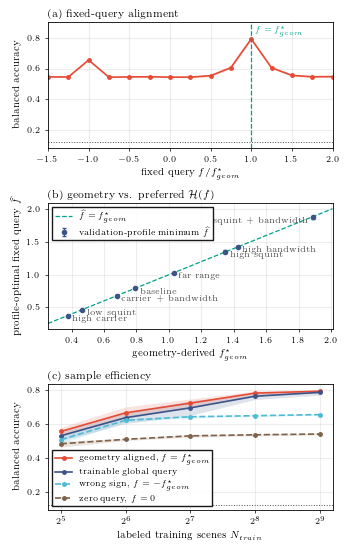

saved /home/felix/SAR-QML/notebooks/sar_fixed_query_outputs/sar_fixed_query_figure_paper_0033ff2273a7.pdf


In [16]:
# =============================================================================
# PRX Quantum manuscript figure: three stacked panels
# =============================================================================
COLORS = {
    "aligned": "#E64B35",
    "mismatched": "#4DBBD5",
    "none": "#7E6148",
    "learned": "#3C5488",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}
LABELS = {
    "aligned": r"geometry aligned, $f=f^\star_{geom}$",
    "mismatched": r"wrong sign, $f=-f^\star_{geom}$",
    "none": r"zero query, $f=0$",
    "learned": "trainable global query",
}

fig = plt.figure(figsize=(3.375, 5.4), layout="constrained")
fig.get_layout_engine().set(h_pad=0.05, hspace=0.06)
axes = fig.subplots(3, 1)

# (a) fixed-query scan
axis = axes[0]
axis.fill_between(
    SCAN_X,
    SCAN_SUMMARY["lower"],
    SCAN_SUMMARY["upper"],
    color=COLORS["aligned"],
    alpha=0.20,
    linewidth=0,
)
axis.plot(
    SCAN_X,
    SCAN_SUMMARY["mean"],
    color=COLORS["aligned"],
    marker="o",
    ms=2.5,
)
axis.axvline(1.0, color=COLORS["geometry"], ls="--", lw=0.9)
axis.axhline(1.0 / Q, color=COLORS["reference"], ls=":", lw=0.7)
axis.annotate(
    r"$f=f^\star_{geom}$",
    xy=(1.0, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=(2.5, -3),
    textcoords="offset points",
    color=COLORS["geometry"],
    fontsize=6.0,
    va="top",
)
peak_value = float(SCAN_SUMMARY["mean"].max())
axis.set_xlim(SCAN_X.min(), SCAN_X.max())
axis.set_xlabel(r"fixed query $f/f^\star_{geom}$")
axis.set_ylabel("balanced accuracy")
axis.set_title("(a) fixed-query alignment", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.set_ylim(1.0 / Q - 0.04, peak_value + 0.11)

# (b) fixed-query profile minimum for each acquisition
axis = axes[1]
predicted = PROFILE_SUMMARY["f_geometry"].to_numpy()
fitted = PROFILE_SUMMARY["f_hat"].to_numpy()
lower = fitted - PROFILE_SUMMARY["f_lower95"].to_numpy()
upper = PROFILE_SUMMARY["f_upper95"].to_numpy() - fitted
span = np.array([min(predicted.min(), fitted.min()), max(predicted.max(), fitted.max())])
padding = 0.08 * max(span[1] - span[0], 1e-3)
span = np.array([span[0] - padding, span[1] + padding])
axis.plot(
    span,
    span,
    color=COLORS["geometry"],
    ls="--",
    lw=0.9,
    label=r"$\widehat f=f^\star_{geom}$",
)



axis.errorbar(
    predicted,
    fitted,
    yerr=np.vstack([lower, upper]),
    fmt="o",
    ms=3.0,
    color=COLORS["learned"],
    ecolor=COLORS["learned"],
    elinewidth=0.7,
    capsize=1.5,
    label=r"validation-profile minimum $\widehat f$",
)
axis.set_xlim(*span)

for x_value, y_value, name in zip(
    predicted, fitted, PROFILE_SUMMARY["geometry"]
):
    flip = x_value > span[0] + 0.7 * (span[1] - span[0])
    axis.annotate(
        name,
        xy=(x_value, y_value),
        xytext=(-3.0 if flip else 3.0, -4.5),
        textcoords="offset points",
        ha="right" if flip else "left",
        fontsize=5.8,
        color=COLORS["reference"],
    )
# for x_value, y_value, name in zip(
#     predicted, fitted, PROFILE_SUMMARY["geometry"]
# ):
#     axis.annotate(
#         name,
#         xy=(x_value, y_value),
#         xytext=(3.0, -4.5),
#         textcoords="offset points",
#         fontsize=5.8,
#         color=COLORS["reference"],
#     )
axis.set_xlabel(r"geometry-derived $f^\star_{geom}$")
axis.set_ylabel(r"profile-optimal fixed query $\widehat f$")
axis.set_title(r"(b) geometry vs. preferred $\mathcal{H}(f)$", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    frameon=True,
        framealpha=0.9,
        edgecolor="black",
        fancybox=False,
    loc="upper left",
)

# (c) sample efficiency
axis = axes[2]
for arm in ("aligned", "learned", "mismatched", "none"):
    summary = EFFICIENCY_SUMMARY[arm]
    axis.fill_between(
        summary["n"],
        summary["lower"],
        summary["upper"],
        color=COLORS[arm],
        alpha=0.16,
        linewidth=0,
    )
    axis.plot(
        summary["n"],
        summary["mean"],
        color=COLORS[arm],
        marker="o",
        ms=2.5,
        ls="-" if arm in ("aligned", "learned") else "--",
        label=LABELS[arm],
    )
axis.axhline(1.0 / Q, color=COLORS["reference"], ls=":", lw=0.7)
axis.set_xscale("log", base=2)
axis.set_xlabel(r"labeled training scenes $N_{train}$")
axis.set_ylabel("balanced accuracy")
axis.set_title("(c) sample efficiency", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    frameon=True,
        framealpha=0.9,
        edgecolor="black",
        fancybox=False,
    loc="lower left",
)

figure_stem = OUTDIR / f"sar_fixed_query_figure_{PROFILE}_{RUN_ID}"
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {figure_stem.with_suffix('.pdf').resolve()}")


## Summary, caption, and scope

**Scope.** This is a controlled SAR-like spectral phase-history simulation,
not measured raw SAR. Its purpose is to isolate one geometry-determined,
nonseparable phase interaction and test whether fixing the corresponding
non-absorbable query selects a useful hypothesis class. The result does not
establish quantum advantage, state-preparation efficiency, or performance
when the local bilinear approximation to the $\omega$--$k$ surface fails.


In [ ]:
# =============================================================================
# Manuscript numbers and caption
# =============================================================================
SUMMARY = {
    "profile": PROFILE,
    "run_id": RUN_ID,
    "geometry": GEOMETRY_SUMMARY,
    "validity": {
        key: (value if isinstance(value, (bool, np.bool_)) else float(value))
        for key, value in VALIDITY.items()
    },
    "audit": AUDIT,
    "calibrated_accuracy": TASK_ACCURACY,
    "efficiency": {
        arm: {
            "n": EFFICIENCY_SUMMARY[arm]["n"].tolist(),
            "mean": np.asarray(EFFICIENCY_SUMMARY[arm]["mean"]).tolist(),
            "lower95": np.asarray(EFFICIENCY_SUMMARY[arm]["lower"]).tolist(),
            "upper95": np.asarray(EFFICIENCY_SUMMARY[arm]["upper"]).tolist(),
        }
        for arm in ARMS
    },
    "geometry_profiles": PROFILE_SUMMARY.to_dict(orient="records"),
    "geometry_profile_curves": PROFILE_CURVE_SUMMARY.to_dict(
        orient="records"
    ),
    "geometry_profile_draw_minima": PROFILE_DRAW_MINIMA.to_dict(
        orient="records"
    ),
    "paired_effects_by_training_size": PAIRED_EFFECTS_BY_N.to_dict(
        orient="records"
    ),
    "scan_paired_advantage": SCAN_PAIRED_ADVANTAGE.to_dict(orient="records"),
}
summary_path = OUTDIR / f"sar_fixed_query_summary_{PROFILE}_{RUN_ID}.json"
summary_path.write_text(json.dumps(SUMMARY, indent=2))

FIGURE_CAPTION = r"""\textbf{A geometry-selected hypothesis class for a
SAR-like spectral task.} Every circuit uses the same %d variational circuit
parameters, the same phase-history patches, and paired initializations; the
trainable-query arm additionally optimizes one global scalar. The
acquisition fixes one query
$f^\star_{geom}=R_0\kappa_{xr}\Delta k_x\Delta k_r$ for the complete dataset.
Its upload $\exp[-i(f/L)\widetilde A\widetilde D]$ has operator-Schmidt rank
larger than one across the azimuth--range partition and cannot be absorbed
into the product trainable blocks. (a) Test accuracy after fitting each
fixed-query class $\mathcal H(f)$; the maximum is consistent with the
geometry-derived value. (b) For each acquisition, $\boldsymbol\theta$ is
retrained over a grid of fixed queries and $\widehat f$ is selected from
held-out validation loss; the resulting profile minima are compared with
the independent geometric prediction. (c) Sample efficiency for the aligned query, a
trainable global query, the equally entangling wrong-sign control, and the
$x$-only circuit. Bands are 95\%% bootstrap intervals over independent
paired scene draws; paired differences are reported in the accompanying
analysis.""" % (
    N_VARIATIONAL_PARAMETERS,
)
caption_path = OUTDIR / f"caption_fixed_query_{PROFILE}_{RUN_ID}.tex"
caption_path.write_text(FIGURE_CAPTION)

print(f"saved {summary_path.resolve()}")
print(PAIRED_EFFECTS_BY_N.to_string(index=False))


saved /home/felix/SAR-QML/notebooks/sar_fixed_query_outputs/sar_fixed_query_summary_paper_0033ff2273a7.json
   control  n_train     mean   lower95  upper95
mismatched       32 0.048360  0.018061 0.079387
mismatched       64 0.043884  0.011189 0.080323
mismatched      128 0.080343  0.057534 0.104390
mismatched      256 0.133464  0.118673 0.147013
mismatched      512 0.138062  0.132202 0.144023
      none       32 0.072917  0.040709 0.106188
      none       64 0.156494  0.126585 0.188375
      none      128 0.193298  0.170125 0.217652
      none      256 0.246134  0.235413 0.256246
      none      512 0.252848  0.243693 0.258748
   learned       32 0.025350  0.007324 0.043437
   learned       64 0.028483 -0.000244 0.059431
   learned      128 0.028097  0.006591 0.054566
   learned      256 0.018453  0.003845 0.036052
   learned      512 0.006938 -0.001099 0.022461
